slam
ausopen       63.642501
frenchopen    62.147019
usopen        63.468184
wimbledon     66.085176
Name: server_won, dtype: float64
len(points): 757326


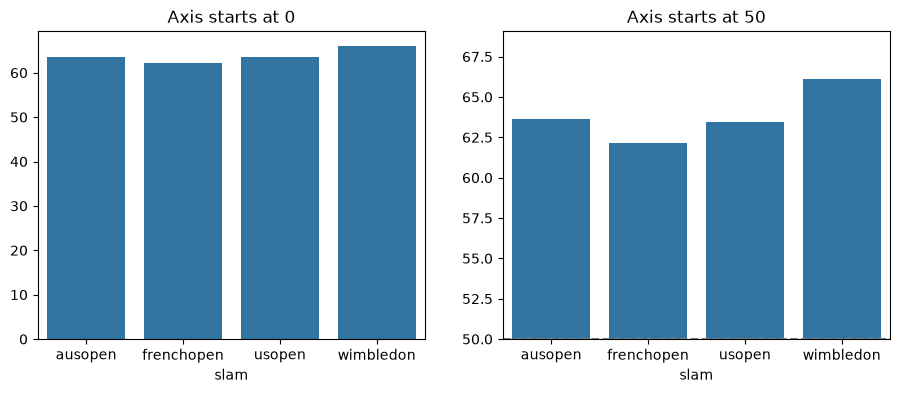

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Load the points table and keep only the training years
ROOT = Path.cwd().parent          # the notebook folder's parent = project root
points = pd.read_parquet(ROOT / "data" / "processed" / "points_men.parquet")

# TODO: keep only rows where the "split" column equals "train"
mask = points["split"] == "train"
points = points[mask].copy()

# 2. Make a column that is 1 when the server won the point, else 0
# Hint: "server" and "point_winner" both hold 1 or 2
# TODO: points["server_won"] = ...
points["server_won"] = (points["server"] == points["point_winner"]).astype(int)

# 3. What share of points does the server win overall, and for each slam?
# Hint: groupby("slam"), then mean(); multiply by 100 for a percentage
# TODO
share_by_slam = points.groupby("slam")["server_won"].mean() * 100
print(share_by_slam)
print(f"len(points): {len(points)}")


# 4. Plot the per-slam numbers as a bar chart
# Hint: sns.barplot(x=..., y=...); label your axes
# TODO
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Version A: the default, y-axis starts at 0
sns.barplot(x=share_by_slam.index, y=share_by_slam.values, ax=axes[0])
axes[0].set_title("Axis starts at 0")

# Version B: y-axis starts at 50
sns.barplot(x=share_by_slam.index, y=share_by_slam.values, ax=axes[1])
axes[1].set_ylim(50, share_by_slam.max() + 3)
axes[1].axhline(50, color="gray", linestyle="--")
axes[1].set_title("Axis starts at 50")

plt.show()

# 5. Write one sentence: what did you find, and why might it be true?
# I found that servers win 60-65% of points, implying a slight advantage for the server. Also, Wimbledon has the highest share of points won by the server, perhaps implying that a grass surface favors the server the most out of all surfaces.

# Prediction

My prediction is that servers on break point will win a lower share of points because they will be thinking about not losing the point and that will distract them. As well as the opponent giving everything they have on that point to win since they can get a valuable break.

In [ ]:
import numpy as np

# 1. Remove tiebreak points: they have different rules
# TODO: keep rows where is_tiebreak == 0 (hint: same mask idea as before)
mask = points["is_tiebreak"] == 0
points = points[mask].copy()

# 2. For each point, get the server's points and the returner's points
# Columns: p1_pts, p2_pts hold 0,1,2,3 for 0/15/30/40 and 4 for advantage
# "server" tells you whether player 1 or 2 is serving
# Hint: np.where(condition, value_if_true, value_if_false)
server_pts = np.where(points["server"] == 1, points["p1_pts"], points["p2_pts"])
returner_pts = np.where(points["server"] == 2, points["p1_pts"], points["p2_pts"])

# 3. Define two True/False columns
# break point: the returner is one point from winning the game
#   (returner has at least 3 points AND more than the server)
# game point: the same idea, from the server's side
break_pts = (returner_pts >= 3) & (returner_pts > server_pts)
game_pts = (server_pts >= 3) & (server_pts > returner_pts)

# 4. Server win rate for break points, game points, and everything else
# Hint: groupby on a True/False column works just like groupby on slam
# TODO

points["situation"] = np.select(
    [break_pts, game_pts],
    ["break", "game"],
    default="everything else"
)

print(points.groupby("situation")["server_won"].agg(["mean", "size"]))
# 5. Write your sentence, using exact numbers
# on a break opportunity, the server won 61% of points. On a game point opportunity, the server won 66% of points. 

                     mean    size
situation                        
break            0.610060   62025
everything else  0.639405  525309
game             0.656998  145078
